In [1]:
import zipfile
import os

zip_path = r"C:\Users\akshitha\Downloads\FlowerClassifier.zip"

# Extraction folder
extract_path = os.path.join(os.path.dirname(zip_path), "TaxoBloom_dataset")

# Create folder if not exists
os.makedirs(extract_path, exist_ok=True)

# Extract ZIP
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Extracted to:", extract_path)

Extracted to: C:\Users\akshitha\Downloads\TaxoBloom_dataset


In [2]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import os

base_path = r"C:\Users\akshitha\Downloads\FlowerClassifier\FlowerClassifier\Final_Data"

train_dir = os.path.join(base_path, "train")
val_dir = os.path.join(base_path, "validation")
test_dir = os.path.join(base_path, "test")

img_size = (224, 224)
batch_size = 32

train_gen = ImageDataGenerator(rescale=1/255)
val_gen = ImageDataGenerator(rescale=1/255)
test_gen = ImageDataGenerator(rescale=1/255)

train_data = train_gen.flow_from_directory(
    train_dir, target_size=img_size, batch_size=batch_size, class_mode='categorical'
)

val_data = val_gen.flow_from_directory(
    val_dir, target_size=img_size, batch_size=batch_size, class_mode='categorical'
)

test_data = test_gen.flow_from_directory(
    test_dir, target_size=img_size, batch_size=batch_size, class_mode='categorical'
)

Found 349 images belonging to 10 classes.
Found 84 images belonging to 10 classes.
Found 86 images belonging to 10 classes.


In [3]:
import os

train_dir = r"C:\Users\akshitha\Downloads\FlowerClassifier\FlowerClassifier\Final_Data\train"

folders = sorted([d for d in os.listdir(train_dir) if os.path.isdir(os.path.join(train_dir, d))])
print("MODEL CLASS ORDER:\n", folders)


MODEL CLASS ORDER:
 ['Calotropis', 'Clitoria', 'Crinum', 'Hibiscus', 'Ixora', 'Lotus', 'Sunflower', 'Tridax', 'periwinkle', 'rose']


In [4]:
import tensorflow as tf

model = tf.keras.Sequential([
    tf.keras.layers.Conv2D(32, (3,3), activation='relu', input_shape=(224,224,3)),
    tf.keras.layers.MaxPooling2D(2,2),

    tf.keras.layers.Conv2D(64, (3,3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2,2),

    tf.keras.layers.Conv2D(128, (3,3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2,2),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.4),

    tf.keras.layers.Dense(train_data.num_classes, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

C:\Users\akshitha\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,170,250 (42.61 MB)

 Trainable params: 11,170,250 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

In [5]:
history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=15
)

Epoch 1/15
11/11 ━━━━━━━━━━━━━━━━━━━━ 15s 1s/step - accuracy: 0.0802 - loss: 3.0617 - val_accuracy: 0.2262 - val_loss: 2.2945
Epoch 2/15
11/11 ━━━━━━━━━━━━━━━━━━━━ 6s 543ms/step - accuracy: 0.1605 - loss: 2.2500 - val_accuracy: 0.2024 - val_loss: 2.2005
Epoch 3/15
11/11 ━━━━━━━━━━━━━━━━━━━━ 6s 543ms/step - accuracy: 0.2464 - loss: 2.0730 - val_accuracy: 0.2143 - val_loss: 2.1032
Epoch 4/15
11/11 ━━━━━━━━━━━━━━━━━━━━ 6s 547ms/step - accuracy: 0.3410 - loss: 1.8752 - val_accuracy: 0.3095 - val_loss: 1.9263
Epoch 5/15
11/11 ━━━━━━━━━━━━━━━━━━━━ 6s 551ms/step - accuracy: 0.4441 - loss: 1.5949 - val_accuracy: 0.4524 - val_loss: 1.6987
Epoch 6/15
11/11 ━━━━━━━━━━━━━━━━━━━━ 6s 535ms/step - accuracy: 0.6017 - loss: 1.2221 - val_accuracy: 0.5714 - val_loss: 1.4831
Epoch 7/15
11/11 ━━━━━━━━━━━━━━━━━━━━ 6s 542ms/step - accuracy: 0.6963 - loss: 0.9453 - val_accuracy: 0.5000 - val_loss: 1.5287
Epoch 8/15
11/11 ━━━━━━━━━━━━━━━━━━━━ 6s 542ms/step - accuracy: 0.7421 - loss: 0.7794 - val_accuracy: 0.61

In [6]:
model.save("TaxoBloom_model.h5")
print("Model saved as TaxoBloom_model.h5")

Model saved as TaxoBloom_model.h5


In [7]:
class_names = train_data.class_indices
class_names = list(class_names.keys())

In [8]:
#this is not required
from tensorflow.keras.preprocessing import image
import numpy as np

# Use class names directly from generator
class_names = train_data.class_indices
class_names = list(class_names.keys())

# Path to the test image
img_path = r"C:\Users\akshitha\Downloads\FlowerClassifier\FlowerClassifier\Final_Data\test\Calotropis\calo_25.jpeg"

# Load image
img = image.load_img(img_path, target_size=(224, 224))
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0) / 255.0

# Predict
prediction = model.predict(img_array)
predicted_class_index = np.argmax(prediction)

print("Predicted Class:", class_names[predicted_class_index])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 192ms/step
Predicted Class: Calotropis


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step


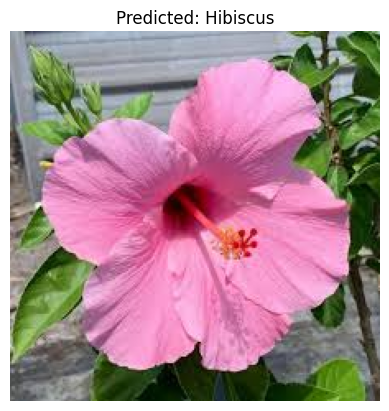

Predicted Class: Hibiscus


In [9]:
from tensorflow.keras.preprocessing import image
import numpy as np
import matplotlib.pyplot as plt

# Use class names directly from generator
class_names = train_data.class_indices
class_names = list(class_names.keys())

# Path to the test image
img_path = r"C:\Users\akshitha\Downloads\FlowerClassifier\FlowerClassifier\Final_Data\train\Hibiscus\hibi_030.jpg"

# Load image
img = image.load_img(img_path, target_size=(224, 224))
img_array = image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0) / 255.0

# Predict
prediction = model.predict(img_array)
predicted_class_index = np.argmax(prediction)
predicted_label = class_names[predicted_class_index]

# Show image
plt.imshow(image.load_img(img_path))
plt.axis("off")
plt.title(f"Predicted: {predicted_label}")
plt.show()

print("Predicted Class:", predicted_label)